# 11. Can a model with satellite signals see the decline?

Neither greenness index showed the decline of clipped biomass (notebooks 4, 5 and 8). This notebook gives a model everything Landsat records, and tests it on years it has not seen. docs/design.md set the rules before any model was fitted:

- **The ladder.** Predictors are added in five rungs: the weather, greenness, all six bands, the shape of the season, and the herds. Every predictor is a site's departure from its own average.
- **Two models at every rung.** A straight line fitted zone by zone, as in the weather model, and boosted trees with their default settings.
- **Leaving a year out.** Each year of 2011–2020 is left out in turn. The model is fitted to the other nine, with each site's averages taken over those nine, and estimates the year left out. What it leaves unexplained is that year's remainder.
- **The pass mark.** The weather rung is the reference. A rung sees the decline when it removes at least half of the reference trend and its 95% range includes zero.

- **Reads** `model_site_years.csv` from `data/processed/`.
- **Writes** nothing.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from mn_desertification import model, paths, trends
from mn_desertification.rules import MAIN_YEARS, ZONES

table = pd.read_csv(paths.PROCESSED_DIR / "model_site_years.csv")
decade = table[table["year"].between(*MAIN_YEARS)]
print("Site-years 2011-2020:", len(decade), "| sites:", decade["gid"].nunique())
for rung in model.RUNGS:
    print(f"   {rung}: {len(model.predictors_up_to(rung))} predictors in all")

Site-years 2011-2020: 13367 | sites: 1485
   1 weather: 2 predictors in all
   2 greenness: 3 predictors in all
   3 all bands: 12 predictors in all
   4 the season: 42 predictors in all
   5 herds: 43 predictors in all


## One year left out, by hand

The nine years other than 2020 are given to the weather model, which then estimates 2020. `departure` is how far a site's 2020 biomass was from its average over the other nine years, `estimate` is what the model made of it, and `remainder` is the first minus the second.

In [2]:
# One year left out, by hand: the model is fitted to the other nine years and estimates 2020
weather_only = model.predictors_up_to("1 weather")
left_out = model.estimate_unseen(decade[decade["year"] != 2020], decade[decade["year"] == 2020], weather_only, "line")
print("Sites estimated in 2020:", len(left_out))
print("Mean departure of 2020 from the sites' averages over the other years:", round(left_out["departure"].mean(), 3))
print("Mean estimate from the weather:", round(left_out["estimate"].mean(), 3), "| mean remainder:", round(left_out["remainder"].mean(), 3))
left_out.head(3).round(3)

Sites estimated in 2020: 1396
Mean departure of 2020 from the sites' averages over the other years: -0.16
Mean estimate from the weather: 0.087 | mean remainder: -0.247


,gid,year,zone,departure,estimate,remainder
13,1,2020,Forest steppe zone,0.247,0.038,0.209
27,2,2020,Forest steppe zone,-0.140,-0.004,-0.136
41,3,2020,Forest steppe zone,0.188,-0.002,0.190


In 2020 the sites were 0.16 below their averages, in log10. The weather alone expected a slightly better year than average: the drought of 2020 struck the south-central Gobi (notebook 1), and taken over the whole country the weather was not dry. So the remainder is large.

## The reference and the ladder

In [3]:
# Every year left out in turn, with the weather alone: the reference for the ladder
reference = model.leave_year_out(decade, weather_only, "line")
reference_trend, low, high = trends.mean_trend(reference)
print(f"Trend of what the weather leaves unexplained: {reference_trend:.3f} per decade (95% range {low:+.3f} to {high:+.3f})")
print("Share of year-to-year change explained in the years left out:", f"{model.skill(reference):.1%}")
trends.yearly_mean(reference).round(3).to_frame("mean remainder").T

Trend of what the weather leaves unexplained: -0.267 per decade (95% range -0.516 to -0.018)
Share of year-to-year change explained in the years left out: 7.9%


year,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
mean remainder,0.136,0.102,0.014,0.012,-0.055,0.123,-0.166,0.016,0.014,-0.247


The reference trend is −0.267 log10 per decade. It is the decline of notebook 2, measured more strictly: a year left out no longer pulls its sites' averages towards itself, and the weather's effect is fitted without it.

In [4]:
# The ladder: five rungs, two models at each. About a minute.
ladder_rows, left_out_by = [], {}
for rung in model.RUNGS:
    for kind in ["line", "trees"]:
        result = model.leave_year_out(decade, model.predictors_up_to(rung), kind)
        left_out_by[(rung, kind)] = result
        trend, low, high = trends.mean_trend(result)
        removed = 1 - trend / reference_trend
        ladder_rows.append({"rung": rung, "model": kind, "skill": round(model.skill(result), 3),
                            "trend left": round(trend, 3), "95% range": f"{low:+.3f} to {high:+.3f}",
                            "share of the trend removed": f"{removed:.0%}",
                            "sees the decline": bool(removed >= 0.5 and low <= 0 <= high)})
ladder = pd.DataFrame(ladder_rows)
ladder

,rung,model,skill,trend left,95% range,share of the trend removed,sees the decline
0,1 weather,line,0.079,-0.267,-0.516 to -0.018,0%,False
1,1 weather,trees,0.057,-0.266,-0.471 to -0.061,0%,False
2,2 greenness,line,0.190,-0.248,-0.397 to -0.098,7%,False
3,2 greenness,trees,0.166,-0.225,-0.367 to -0.083,16%,False
4,3 all bands,line,0.190,-0.226,-0.374 to -0.077,15%,False
5,3 all bands,trees,0.178,-0.206,-0.330 to -0.082,23%,False
6,4 the season,line,0.178,-0.199,-0.340 to -0.058,26%,False
7,4 the season,trees,0.186,-0.192,-0.303 to -0.081,28%,False
8,5 herds,line,0.212,-0.016,-0.181 to +0.148,94%,True
9,5 herds,trees,0.232,-0.046,-0.162 to +0.069,83%,True


- **Greenness more than doubles the skill,** from 7.9% to 19.0% of the sites' year-to-year change.
- **The other bands and the season add nothing to it.**
- **No satellite rung sees the decline.** All the satellite signals together remove 26% to 28% of the reference trend, and what is left has a range that excludes zero.
- **The two models agree,** so this does not depend on the model's form.
- **The herds rung passes the mark.** The check at the end of this notebook looks at why.

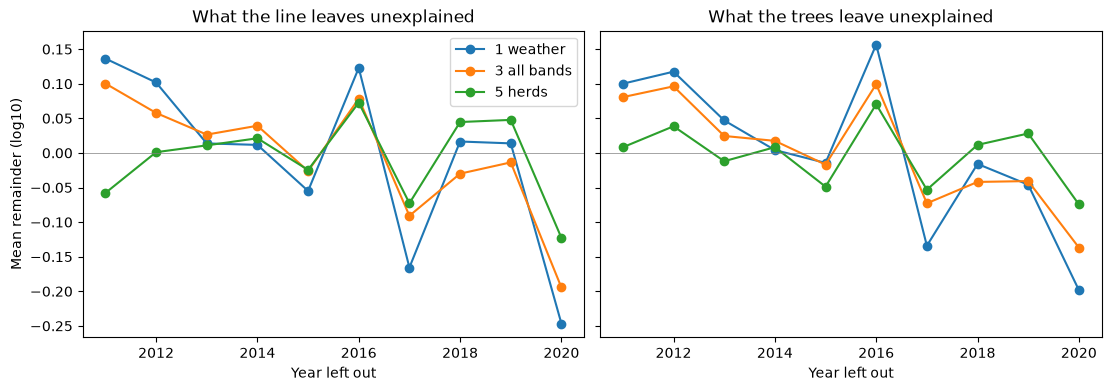

year,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
"1 weather, line",0.136,0.102,0.014,0.012,-0.055,0.123,-0.166,0.016,0.014,-0.247
"1 weather, trees",0.100,0.117,0.047,0.004,-0.014,0.157,-0.134,-0.016,-0.046,-0.198
"4 the season, line",0.070,0.073,0.038,0.035,-0.026,0.065,-0.089,-0.004,-0.007,-0.177
"4 the season, trees",0.070,0.089,0.037,0.012,-0.011,0.081,-0.071,-0.028,-0.034,-0.133
"5 herds, line",-0.058,0.001,0.011,0.021,-0.025,0.073,-0.073,0.045,0.048,-0.123
"5 herds, trees",0.008,0.039,-0.012,0.008,-0.049,0.070,-0.053,0.012,0.028,-0.074


In [5]:
# Year by year: what is left unexplained at three rungs, for each model
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True, layout="constrained")
for ax, kind in zip(axes, ["line", "trees"]):
    for rung in ["1 weather", "3 all bands", "5 herds"]:
        yearly = trends.yearly_mean(left_out_by[(rung, kind)])
        ax.plot(yearly.index, yearly.values, marker="o", label=rung)
    ax.axhline(0, color="grey", linewidth=0.5)
    ax.set_title(f"What the {kind} leave unexplained" if kind == "trees" else "What the line leaves unexplained")
    ax.set_xlabel("Year left out")
axes[0].set_ylabel("Mean remainder (log10)")
axes[0].legend()
plt.show()
pd.DataFrame({f"{rung}, {kind}": trends.yearly_mean(left_out_by[(rung, kind)])
              for rung in ["1 weather", "4 the season", "5 herds"] for kind in ["line", "trees"]}).round(3).T

In [6]:
# Zone by zone: the trend left by the weather alone, by every satellite signal, and with the herds
zone_rows = []
for zone in ZONES:
    row = {"zone": zone}
    for label, key in [("weather", ("1 weather", "line")), ("satellites, line", ("4 the season", "line")),
                       ("satellites, trees", ("4 the season", "trees")), ("with herds, trees", ("5 herds", "trees"))]:
        result = left_out_by[key]
        trend, low, high = trends.mean_trend(result[result["zone"] == zone])
        row[label] = f"{trend:+.3f} ({low:+.2f} to {high:+.2f})"
    zone_rows.append(row)
pd.DataFrame(zone_rows)

,zone,weather,"satellites, line","satellites, trees","with herds, trees"
0,Desert zone,-0.521 (-0.98 to -0.06),-0.422 (-0.82 to -0.03),-0.402 (-0.77 to -0.04),-0.136 (-0.47 to +0.20)
1,Semi desert steppe zone,-0.528 (-0.87 to -0.19),-0.385 (-0.71 to -0.06),-0.352 (-0.59 to -0.12),-0.141 (-0.39 to +0.10)
2,Steppe zone,-0.279 (-0.51 to -0.05),-0.192 (-0.33 to -0.06),-0.209 (-0.33 to -0.09),-0.065 (-0.19 to +0.06)
3,Forest steppe zone,+0.008 (-0.44 to +0.46),-0.025 (-0.29 to +0.24),+0.003 (-0.22 to +0.23),+0.078 (-0.16 to +0.31)
4,Mountain taiga belt,-0.029 (-0.23 to +0.17),+0.040 (-0.20 to +0.27),+0.001 (-0.16 to +0.16),+0.050 (-0.11 to +0.21)


The satellite signals pull both ends of the decade towards zero, but not far enough. In the three dry zones they remove between a fifth and a third of the decline.

## What in the herds removes the trend?

This check was added after the ladder and was not set in advance. The herds rose in every year of the decade, so a herd count is close to a clock. Each count is split into the country's herd of that year, the same for every site, and the soum's own departure from it. The calendar year is also tried in place of the herds.

In [7]:
# A check added after the ladder: what in the herds removes the trend? A herd count has two parts:
# the country's herd of that year, the same for every site, and the soum's own departure from it
checked = decade.copy()
checked["calendar_year"] = checked["year"].astype(float)
checked["herd_of_the_country"] = checked.groupby("year")["log_herd"].transform("mean")
checked["herd_of_the_soum_only"] = checked["log_herd"] - checked["herd_of_the_country"]

satellites = model.predictors_up_to("4 the season")
check_rows = []
for label, extra in [("satellites only", []), ("+ herds (rung 5)", ["log_herd"]), ("+ the calendar year instead", ["calendar_year"]),
                     ("+ the country's herd only", ["herd_of_the_country"]), ("+ the soum's own part only", ["herd_of_the_soum_only"])]:
    for kind in ["line", "trees"]:
        result = model.leave_year_out(checked, satellites + extra, kind)
        trend, low, high = trends.mean_trend(result)
        check_rows.append({"predictors": label, "model": kind, "skill": round(model.skill(result), 3), "trend left": round(trend, 3),
                           "95% range": f"{low:+.3f} to {high:+.3f}", "share of the trend removed": f"{1 - trend / reference_trend:.0%}"})
pd.DataFrame(check_rows)

,predictors,model,skill,trend left,95% range,share of the trend removed
0,satellites only,line,0.178,-0.199,-0.340 to -0.058,26%
1,satellites only,trees,0.186,-0.192,-0.303 to -0.081,28%
2,+ herds (rung 5),line,0.212,-0.016,-0.181 to +0.148,94%
3,+ herds (rung 5),trees,0.232,-0.046,-0.162 to +0.069,83%
4,+ the calendar year instead,line,0.210,-0.024,-0.182 to +0.133,91%
5,+ the calendar year instead,trees,0.212,-0.081,-0.206 to +0.044,70%
6,+ the country's herd only,line,0.206,-0.025,-0.184 to +0.134,91%
7,+ the country's herd only,trees,0.214,-0.067,-0.193 to +0.059,75%
8,+ the soum's own part only,line,0.189,-0.180,-0.327 to -0.033,33%
9,+ the soum's own part only,trees,0.196,-0.185,-0.303 to -0.066,31%


- **The calendar year does almost as well as the herds,** and so does the country's herd alone.
- **The soum's own part adds little,** about five points more than the satellites alone.
- The herds rung passes the mark as a clock would. It shows that the decline runs steadily through the decade. It does not show that the herds explain it.

## In short

- **Satellites see about a quarter of the decline.** With every Landsat band and the shape of the season, a model that has not seen a year still leaves a trend of about −0.19 log10 per decade, against −0.267 for the weather alone.
- **Greenness carries what the satellites know.** The other four bands and the season do not add to it.
- **A straight line and boosted trees give the same answer.**
- **The herds rung passes the mark only as a steadily rising number would.**
- **A limit.** The test asks whether the signals carry each year's level. It cannot tell a decline the satellites cannot see from one that is not in the land, such as a slow change in how the clipping was done.